<a href="https://colab.research.google.com/github/bunjiro1213/gtzan-music-genre-classification/blob/main/GTZAN_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub librosa soundfile

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import torch
import kagglehub
from pathlib import Path
path = kagglehub.dataset_download(
    "andradaolteanu/gtzan-dataset-music-genre-classification"
)
data_path = Path(path)
print("Dataset location:", data_path)
print("GPU available:", torch.cuda.is_available())

Using Colab cache for faster access to the 'gtzan-dataset-music-genre-classification' dataset.
Dataset location: /kaggle/input/gtzan-dataset-music-genre-classification
GPU available: True


In [2]:
audio_files = sorted(data_path.rglob("*.wav"))
print("Number of audio files:", len(audio_files))
print("First five audio files:")
for file in audio_files[:5]:
    print(file)

Number of audio files: 1000
First five audio files:
/kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original/blues/blues.00000.wav
/kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original/blues/blues.00001.wav
/kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original/blues/blues.00002.wav
/kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original/blues/blues.00003.wav
/kaggle/input/gtzan-dataset-music-genre-classification/Data/genres_original/blues/blues.00004.wav


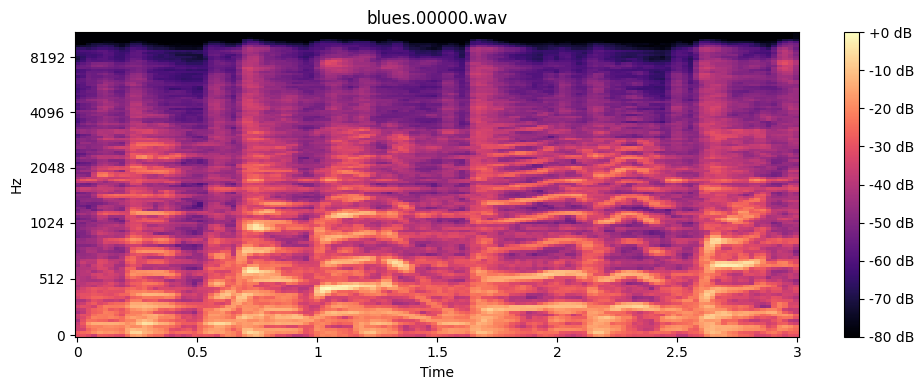

Spectrogram shape: (128, 130)


In [3]:
# Load one song
audio_file = audio_files[0]

y, sr = librosa.load(audio_file, sr=22050)

# Take the first 3 seconds
segment = y[:3 * sr]

# Convert audio into a mel spectrogram
mel = librosa.feature.melspectrogram(
    y=segment,
    sr=sr,
    n_mels=128,
    n_fft=2048,
    hop_length=512
)

mel_db = librosa.power_to_db(mel, ref=np.max)

# Display spectrogram
plt.figure(figsize=(10, 4))

librosa.display.specshow(
    mel_db,
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title(audio_file.name)
plt.tight_layout()
plt.show()

print("Spectrogram shape:", mel_db.shape)

In [4]:
window_size = 3 * sr
spectrograms = []

for i in range(10):
    start = i * window_size
    end = start + window_size

    segment = y[start:end]

    if len(segment) < window_size:
        break

    mel = librosa.feature.melspectrogram(
        y=segment,
        sr=sr,
        n_mels=128,
        n_fft=2048,
        hop_length=512
    )

    mel_db = librosa.power_to_db(mel, ref=np.max)
    spectrograms.append(mel_db)

spectrograms = np.array(spectrograms)

print("Number of windows:", len(spectrograms))
print("Spectrograms shape:", spectrograms.shape)

Number of windows: 10
Spectrograms shape: (10, 128, 130)


In [5]:
import torch

X = torch.tensor(spectrograms, dtype=torch.float32)

# Add channel dimension
X = X.unsqueeze(1)

print("CNN input shape:", X.shape)

CNN input shape: torch.Size([10, 1, 128, 130])


In [6]:
import torch.nn as nn

class GenreCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(32, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [7]:
model = GenreCNN()

output = model(X)

print("Input shape:", X.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([10, 1, 128, 130])
Output shape: torch.Size([10, 10])


In [8]:
def process_song(audio_file):
    y, sr = librosa.load(audio_file, sr=22050, duration=30)

    window_size = 3 * sr

    # Make sure every song has 30 seconds of audio
    if len(y) < 10 * window_size:
        y = np.pad(y, (0, 10 * window_size - len(y)))

    spectrograms = []

    for i in range(10):
        start = i * window_size
        end = start + window_size

        segment = y[start:end]

        mel = librosa.feature.melspectrogram(
            y=segment,
            sr=sr,
            n_mels=128,
            n_fft=2048,
            hop_length=512
        )

        mel_db = librosa.power_to_db(mel, ref=1.0)
        spectrograms.append(mel_db)

    return np.array(spectrograms, dtype=np.float32)

In [9]:
for audio_file in audio_files[:5]:
    result = process_song(audio_file)

    print(audio_file.name, result.shape)

blues.00000.wav (10, 128, 130)
blues.00001.wav (10, 128, 130)
blues.00002.wav (10, 128, 130)
blues.00003.wav (10, 128, 130)
blues.00004.wav (10, 128, 130)


In [10]:
from google.colab import files

uploaded = files.upload()

manifest = pd.read_csv("split_manifest.csv")

print(manifest.head())
print(manifest["split"].value_counts())

Saving split_manifest.csv to split_manifest.csv
          filename  label  split
0  blues.00000.wav  blues  train
1  blues.00001.wav  blues   test
2  blues.00002.wav  blues   test
3  blues.00003.wav  blues  train
4  blues.00004.wav  blues  train
split
train    639
test     200
val      160
Name: count, dtype: int64


In [11]:
audio_by_name = {file.name: file for file in audio_files}

missing = [
    filename for filename in manifest["filename"]
    if filename not in audio_by_name
]

print("Missing audio files:", missing)
print("Number of songs:", len(manifest))

Missing audio files: []
Number of songs: 999


In [12]:
from tqdm.auto import tqdm

genres = sorted(manifest["label"].unique())
genre_to_id = {genre: i for i, genre in enumerate(genres)}

data = {}

for split in ["train", "val", "test"]:
    rows = manifest[manifest["split"] == split]

    X_list = []
    y_list = []

    for row in tqdm(rows.itertuples(index=False), total=len(rows), desc=split):
        audio_file = audio_by_name[row.filename]

        spectrograms = process_song(audio_file)

        X_list.append(spectrograms)
        y_list.append(genre_to_id[row.label])

    X = np.stack(X_list)
    y = np.array(y_list)

    data[split] = (X, y)

    print(split, X.shape, y.shape)

train:   0%|          | 0/639 [00:00<?, ?it/s]

train (639, 10, 128, 130) (639,)


val:   0%|          | 0/160 [00:00<?, ?it/s]

val (160, 10, 128, 130) (160,)


test:   0%|          | 0/200 [00:00<?, ?it/s]

test (200, 10, 128, 130) (200,)


In [13]:
from torch.utils.data import TensorDataset, DataLoader

train_X = data["train"][0]

mean = train_X.mean()
std = train_X.std() + 1e-8

def create_loader(split, batch_size=32):
    X, y = data[split]

    X = (X - mean) / std

    # Convert songs into individual windows
    X = X.reshape(-1, 1, 128, 130)
    y = np.repeat(y, 10)

    X = torch.tensor(X, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.long)

    dataset = TensorDataset(X, y)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=(split == "train")
    )

train_loader = create_loader("train")
val_loader = create_loader("val")
test_loader = create_loader("test")

print("Training windows:", len(train_loader.dataset))
print("Validation windows:", len(val_loader.dataset))
print("Testing windows:", len(test_loader.dataset))

Training windows: 6390
Validation windows: 1600
Testing windows: 2000


In [14]:
import torch
import torch.nn as nn
import torch.optim as optim

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Initialize CNN
model = GenreCNN().to(device)

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

Using device: cuda


In [15]:
import copy

num_epochs = 15
patience = 4

best_val_loss = float("inf")
best_model = None
epochs_without_improvement = 0

for epoch in range(num_epochs):

    # Training
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for X, y in train_loader:
        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        outputs = model(X)
        loss = criterion(outputs, y)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * y.size(0)
        train_correct += (outputs.argmax(dim=1) == y).sum().item()
        train_total += y.size(0)

    # Validation
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for X, y in val_loader:
            X = X.to(device)
            y = y.to(device)

            outputs = model(X)
            loss = criterion(outputs, y)

            val_loss += loss.item() * y.size(0)
            val_correct += (outputs.argmax(dim=1) == y).sum().item()
            val_total += y.size(0)

    train_loss /= train_total
    val_loss /= val_total

    train_acc = train_correct / train_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore best model
model.load_state_dict(best_model)

Epoch 1/15 | Train Loss: 2.1203 | Train Acc: 0.2006 | Val Loss: 2.0152 | Val Acc: 0.2919
Epoch 2/15 | Train Loss: 1.9855 | Train Acc: 0.2585 | Val Loss: 1.9028 | Val Acc: 0.3519
Epoch 3/15 | Train Loss: 1.8659 | Train Acc: 0.3191 | Val Loss: 1.7410 | Val Acc: 0.4238
Epoch 4/15 | Train Loss: 1.7696 | Train Acc: 0.3596 | Val Loss: 1.6494 | Val Acc: 0.4669
Epoch 5/15 | Train Loss: 1.7028 | Train Acc: 0.3834 | Val Loss: 1.5818 | Val Acc: 0.4869
Epoch 6/15 | Train Loss: 1.6667 | Train Acc: 0.3905 | Val Loss: 1.5515 | Val Acc: 0.4806
Epoch 7/15 | Train Loss: 1.6266 | Train Acc: 0.4105 | Val Loss: 1.5061 | Val Acc: 0.4950
Epoch 8/15 | Train Loss: 1.6085 | Train Acc: 0.4166 | Val Loss: 1.4936 | Val Acc: 0.4894
Epoch 9/15 | Train Loss: 1.5871 | Train Acc: 0.4239 | Val Loss: 1.4442 | Val Acc: 0.5112
Epoch 10/15 | Train Loss: 1.5675 | Train Acc: 0.4299 | Val Loss: 1.4288 | Val Acc: 0.4963
Epoch 11/15 | Train Loss: 1.5472 | Train Acc: 0.4341 | Val Loss: 1.4084 | Val Acc: 0.5050
Epoch 12/15 | Train

<All keys matched successfully>

In [16]:
torch.save({
    "model_state_dict": model.state_dict(),
    "genres": genres,
    "mean": float(mean),
    "std": float(std)
}, "genre_cnn_best.pt")

print("Model saved successfully!")

Model saved successfully!


In [17]:
model.eval()

all_probs = []

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)

        outputs = model(X)
        probs = torch.softmax(outputs, dim=1)

        all_probs.append(probs.cpu())

# Combine predictions from all validation windows
all_probs = torch.cat(all_probs)

print("Window probabilities shape:", all_probs.shape)

# Group every 10 windows back into one song
song_probs = all_probs.reshape(-1, 10, 10).mean(dim=1)

# Choose the genre with the highest average probability
song_predictions = song_probs.argmax(dim=1).numpy()

# Actual song labels
song_labels = data["val"][1]

# Calculate song-level accuracy
song_accuracy = np.mean(song_predictions == song_labels)

print("Song-level validation accuracy:", round(song_accuracy * 100, 2), "%")

Window probabilities shape: torch.Size([1600, 10])
Song-level validation accuracy: 56.25 %


In [18]:
from sklearn.metrics import accuracy_score

# Window-level predictions
window_predictions = all_probs.argmax(dim=1).numpy()
window_labels = np.repeat(song_labels, 10)

window_accuracy = accuracy_score(
    window_labels, window_predictions
)

song_accuracy = accuracy_score(
    song_labels, song_predictions
)

print(f"Window-level accuracy: {window_accuracy:.2%}")
print(f"Song-level accuracy: {song_accuracy:.2%}")

Window-level accuracy: 50.88%
Song-level accuracy: 56.25%


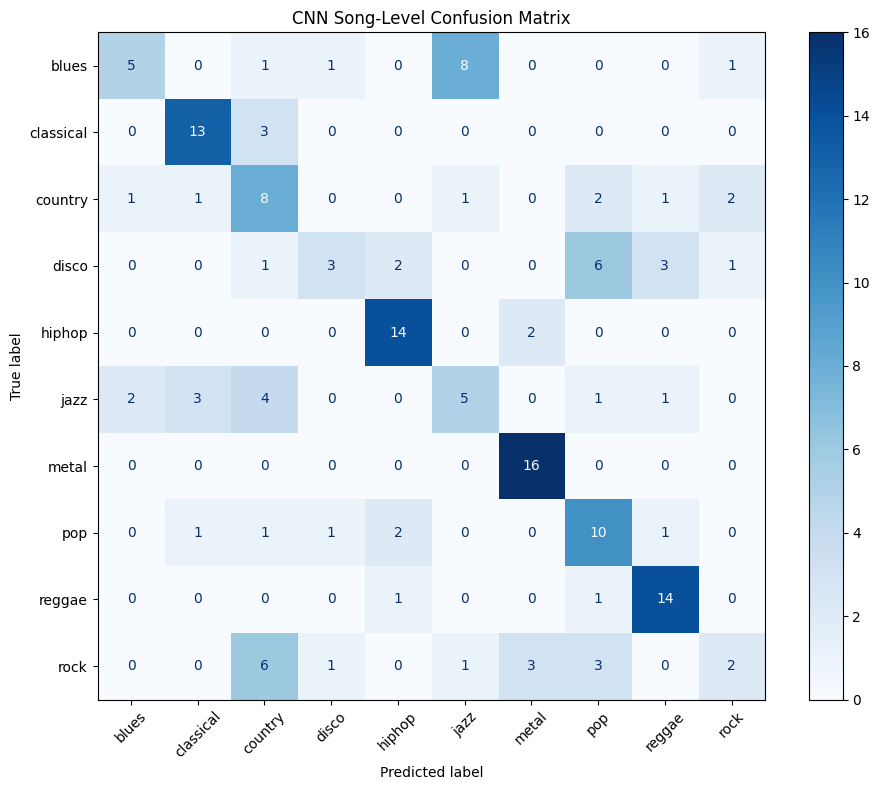

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(song_labels, song_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=genres
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)

plt.title("CNN Song-Level Confusion Matrix")
plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import classification_report

print(classification_report(
    song_labels,
    song_predictions,
    labels=range(len(genres)),
    target_names=genres,
    zero_division=0
))

              precision    recall  f1-score   support

       blues       0.62      0.31      0.42        16
   classical       0.72      0.81      0.76        16
     country       0.33      0.50      0.40        16
       disco       0.50      0.19      0.27        16
      hiphop       0.74      0.88      0.80        16
        jazz       0.33      0.31      0.32        16
       metal       0.76      1.00      0.86        16
         pop       0.43      0.62      0.51        16
      reggae       0.70      0.88      0.78        16
        rock       0.33      0.12      0.18        16

    accuracy                           0.56       160
   macro avg       0.55      0.56      0.53       160
weighted avg       0.55      0.56      0.53       160



In [21]:
val_rows = manifest[manifest["split"] == "val"].reset_index(drop=True)

results = pd.DataFrame({
    "filename": val_rows["filename"],
    "actual": [genres[i] for i in song_labels],
    "predicted": [genres[i] for i in song_predictions],
    "confidence": song_probs.max(dim=1).values.numpy()
})

mistakes = results[results["actual"] != results["predicted"]]

print("Number of incorrect predictions:", len(mistakes))

display(mistakes.head(20))

Number of incorrect predictions: 70


,filename,actual,predicted,confidence
2,blues.00018.wav,blues,jazz,0.319139
3,blues.00028.wav,blues,jazz,0.300966
4,blues.00030.wav,blues,jazz,0.316018
5,blues.00033.wav,blues,jazz,0.356881
6,blues.00034.wav,blues,jazz,0.324007
7,blues.00035.wav,blues,country,0.290693
8,blues.00038.wav,blues,jazz,0.309711
9,blues.00041.wav,blues,rock,0.213195
12,blues.00084.wav,blues,disco,0.221677
13,blues.00085.wav,blues,jazz,0.286065
